# Olist E-commerce Analysis (Python)

This notebook picks up where the SQL analysis leaves off. It:

1. Checks data quality and cleans the raw tables
2. Builds analysis-ready tables (also exported for Excel and Power BI)
3. Explores sales trends, delivery performance and its effect on reviews
4. Segments customers with RFM and measures cohort retention

**Data:** `data/processed/olist.db`, built by `scripts/load_data.py`.
**Analysis window:** Jan 2017 to Aug 2018 (full months only).

In [1]:
import sqlite3
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DB = ROOT / "data" / "processed" / "olist.db"
FIG = ROOT / "notebooks" / "figures"
FIG.mkdir(exist_ok=True)

pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", "{:,.2f}".format)

BLUE, GREY, RED = "#2563eb", "#9ca3af", "#dc2626"
plt.rcParams.update({
    "figure.figsize": (10, 4.5), "figure.dpi": 110, "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3, "axes.titleweight": "bold",
})

con = sqlite3.connect(DB)
tables = ["orders", "customers", "order_items", "order_payments", "order_reviews",
          "products", "sellers", "category_translation"]
df = {t: pd.read_sql_query(f"SELECT * FROM {t}", con) for t in tables}
pd.DataFrame({t: d.shape for t, d in df.items()}, index=["rows", "cols"]).T

,rows,cols
orders,99441,8
customers,99441,5
order_items,112650,7
order_payments,103886,5
order_reviews,99224,7
products,32951,9
sellers,3095,4
category_translation,71,2


## 1. Data quality checks

In [2]:
quality = pd.DataFrame({
    t: {
        "rows": len(d),
        "duplicate_rows": d.duplicated().sum(),
        "cols_with_nulls": int((d.isna().sum() > 0).sum()),
        "total_nulls": int(d.isna().sum().sum()),
    }
    for t, d in df.items()
}).T
quality

,rows,duplicate_rows,cols_with_nulls,total_nulls
orders,99441,0,3,4908
customers,99441,0,0,0
order_items,112650,0,0,0
order_payments,103886,0,0,0
order_reviews,99224,0,2,145903
products,32951,0,8,2448
sellers,3095,0,0,0
category_translation,71,0,0,0


In [3]:
orders = df["orders"].copy()
print("Order status counts:\n", orders["order_status"].value_counts(), "\n")
print("Orders with no items:", (~orders["order_id"].isin(df["order_items"]["order_id"])).sum())
print("Reviews per order > 1:", (df["order_reviews"]["order_id"].value_counts() > 1).sum())
print("Delivered orders missing a delivery date:",
      ((orders["order_status"] == "delivered") & orders["order_delivered_customer_date"].isna()).sum())
print("Products missing a category:", df["products"]["product_category_name"].isna().sum())

Order status counts:
 order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64 

Orders with no items: 775
Reviews per order > 1: 547
Delivered orders missing a delivery date: 8
Products missing a category: 610


**Findings and cleaning decisions**

- 97% of orders are `delivered`. Revenue and delivery metrics use delivered orders only.
- 775 orders have no items (mostly canceled/unavailable) and are dropped.
- A few orders have more than one review, so scores are averaged per order.
- 610 products have no category; they are labelled `unknown`. Two Portuguese categories
  are missing from the translation table and are translated manually.
- `customer_id` is unique per order; `customer_unique_id` identifies the actual person.

## 2. Build clean tables

In [4]:
date_cols = ["order_purchase_timestamp", "order_approved_at", "order_delivered_carrier_date",
             "order_delivered_customer_date", "order_estimated_delivery_date"]
orders[date_cols] = orders[date_cols].apply(pd.to_datetime)

items = df["order_items"].copy()
products = df["products"].merge(df["category_translation"], on="product_category_name", how="left")
products["category"] = (products["product_category_name_english"]
    .fillna(products["product_category_name"].replace({
        "portateis_cozinha_e_preparadores_de_alimentos": "portable_kitchen_appliances"}))
    .fillna("unknown"))

order_totals = items.groupby("order_id").agg(
    n_items=("order_item_id", "count"), revenue=("price", "sum"), freight=("freight_value", "sum"))
reviews = df["order_reviews"].groupby("order_id")["review_score"].mean()
payments = (df["order_payments"].sort_values("payment_value", ascending=False)
            .groupby("order_id").agg(payment_type=("payment_type", "first"),
                                     installments=("payment_installments", "max")))

o = (orders
     .merge(df["customers"], on="customer_id")
     .merge(order_totals, on="order_id")              # inner join drops orders with no items
     .merge(reviews, on="order_id", how="left")
     .merge(payments, on="order_id", how="left"))
o = o[(o["order_purchase_timestamp"] >= "2017-01-01") & (o["order_purchase_timestamp"] < "2018-09-01")]

o["purchase_date"] = o["order_purchase_timestamp"].dt.normalize()
o["purchase_month"] = o["order_purchase_timestamp"].dt.to_period("M").astype(str)
o["delivery_days"] = (o["order_delivered_customer_date"] - o["order_purchase_timestamp"]).dt.total_seconds() / 86400
o["days_vs_estimate"] = (o["order_delivered_customer_date"].dt.normalize()
                         - o["order_estimated_delivery_date"].dt.normalize()).dt.days
o["is_late"] = np.where(o["days_vs_estimate"].isna(), np.nan, (o["days_vs_estimate"] > 0).astype(float))

delivered = o[(o["order_status"] == "delivered") & o["delivery_days"].notna()].copy()
print(f"Clean delivered orders: {len(delivered):,} of {len(o):,} in window")
delivered[["revenue", "freight", "delivery_days", "review_score"]].describe().T

Clean delivered orders: 96,203 of 98,353 in window


,count,mean,std,min,25%,50%,75%,max
revenue,"96,203.00",137.00,209.12,0.85,45.90,86.50,149.90,"13,440.00"
freight,"96,203.00",22.78,21.57,0.00,13.85,17.17,24.01,"1,794.96"
delivery_days,"96,203.00",12.54,9.53,0.53,6.76,10.21,15.68,209.63
review_score,"95,560.00",4.16,1.28,1.00,4.00,5.00,5.00,5.00


Price and freight are right-skewed (a few orders above R$ 1,000), which is normal for
e-commerce. They're real purchases, so they're kept rather than removed as outliers.
Totals match the SQL `kpis` query, which confirms both pipelines agree.

In [5]:
kpis = pd.Series({
    "Orders": len(delivered),
    "Customers": delivered["customer_unique_id"].nunique(),
    "Revenue (R$)": delivered["revenue"].sum(),
    "Avg order value (R$)": delivered["revenue"].mean(),
    "Avg review": delivered["review_score"].mean(),
    "Late deliveries (%)": 100 * delivered["is_late"].mean(),
})
kpis.to_frame("value")

,value
Orders,"96,203.00"
Customers,"93,096.00"
Revenue (R$),"13,179,777.95"
Avg order value (R$),137.00
Avg review,4.16
Late deliveries (%),6.79


## 3. Sales trends

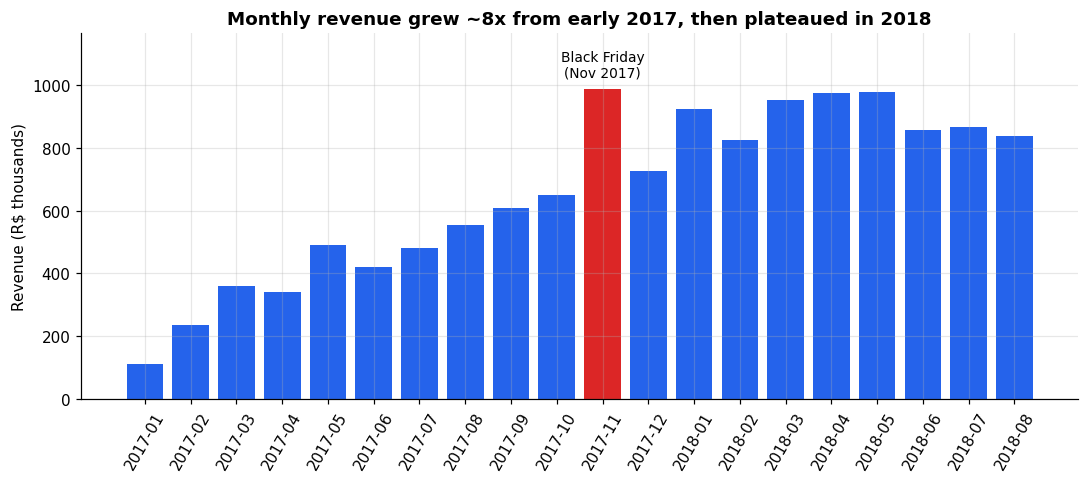

In [6]:
monthly = delivered.groupby("purchase_month").agg(orders=("order_id", "count"), revenue=("revenue", "sum"))
fig, ax = plt.subplots()
ax.bar(monthly.index, monthly["revenue"] / 1e3, color=BLUE)
ax.bar("2017-11", monthly.loc["2017-11", "revenue"] / 1e3, color=RED)
ax.annotate("Black Friday\n(Nov 2017)", ("2017-11", monthly.loc["2017-11", "revenue"] / 1e3),
            xytext=(0, 8), textcoords="offset points", ha="center", fontsize=9)
ax.set_ylim(0, monthly["revenue"].max() / 1e3 * 1.18)
ax.set_title("Monthly revenue grew ~8x from early 2017, then plateaued in 2018")
ax.set_ylabel("Revenue (R$ thousands)")
ax.tick_params(axis="x", rotation=60)
fig.tight_layout(); fig.savefig(FIG / "monthly_revenue.png"); plt.show()

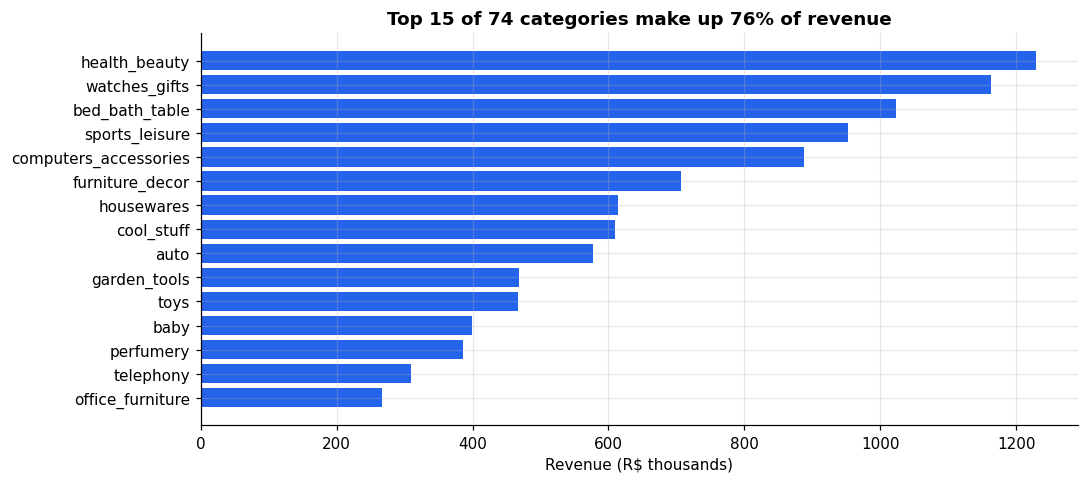

In [7]:
cat_items = items.merge(products[["product_id", "category"]], on="product_id")
cat_items = cat_items[cat_items["order_id"].isin(delivered["order_id"])]
cat = cat_items.groupby("category")["price"].sum().sort_values(ascending=False)
top = cat.head(15)
cum_share = cat.cumsum() / cat.sum() * 100

fig, ax = plt.subplots()
ax.barh(top.index[::-1], top.values[::-1] / 1e3, color=BLUE)
ax.set_title(f"Top 15 of {len(cat)} categories make up {cum_share.iloc[14]:.0f}% of revenue")
ax.set_xlabel("Revenue (R$ thousands)")
fig.tight_layout(); fig.savefig(FIG / "top_categories.png"); plt.show()

## 4. Delivery performance and reviews

The key question: **does late delivery hurt customer satisfaction, and by how much?**

In [8]:
bins = [-np.inf, 0, 3, 7, np.inf]
labels = ["On time / early", "1-3 days late", "4-7 days late", "8+ days late"]
delivered["delivery_bucket"] = pd.cut(delivered["days_vs_estimate"], bins=bins, labels=labels)
by_bucket = delivered.dropna(subset=["review_score"]).groupby("delivery_bucket", observed=True).agg(
    orders=("order_id", "count"),
    avg_review=("review_score", "mean"),
    pct_bad_review=("review_score", lambda s: 100 * (s <= 2).mean()),
)
by_bucket

,orders,avg_review,pct_bad_review
delivery_bucket,,,
On time / early,89182,4.29,9.21
1-3 days late,1851,3.29,32.20
4-7 days late,1748,2.11,67.56
8+ days late,2779,1.70,79.17


Spearman correlation with review score:
 delivery_days      -0.23
days_vs_estimate   -0.18
review_score        1.00
Name: review_score, dtype: float64


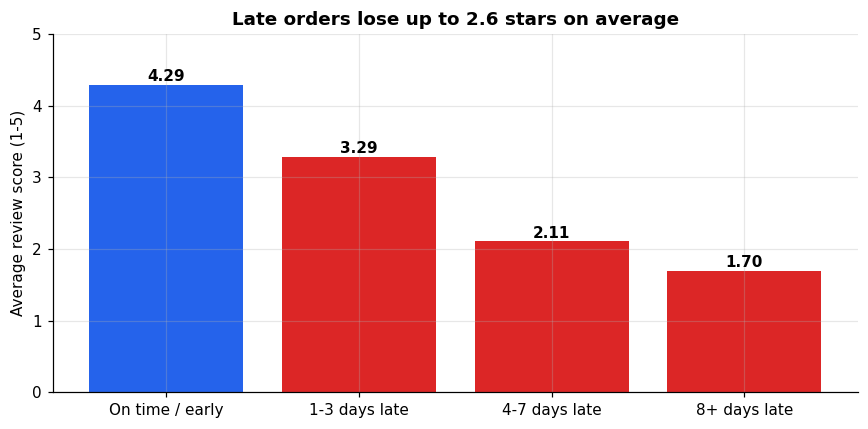

In [9]:
fig, ax = plt.subplots(figsize=(8, 4))
colors = [BLUE] + [RED] * 3
ax.bar(by_bucket.index.astype(str), by_bucket["avg_review"], color=colors)
for i, v in enumerate(by_bucket["avg_review"]):
    ax.text(i, v + 0.05, f"{v:.2f}", ha="center", fontweight="bold")
ax.set_ylim(0, 5)
ax.set_ylabel("Average review score (1-5)")
ax.set_title("Late orders lose up to 2.6 stars on average")
fig.tight_layout(); fig.savefig(FIG / "review_vs_lateness.png"); plt.show()

corr = delivered[["delivery_days", "days_vs_estimate", "review_score"]].corr(method="spearman")
print("Spearman correlation with review score:\n", corr["review_score"].round(3))

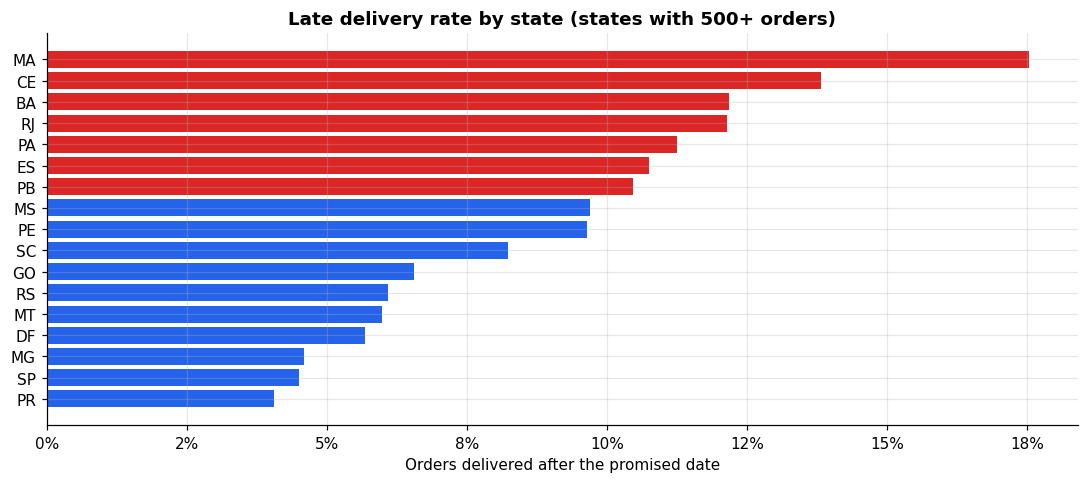

In [10]:
state = delivered.groupby("customer_state").agg(
    orders=("order_id", "count"), avg_delivery_days=("delivery_days", "mean"), late_pct=("is_late", "mean"))
state["late_pct"] *= 100
state = state[state["orders"] >= 500].sort_values("late_pct")

fig, ax = plt.subplots()
ax.barh(state.index, state["late_pct"], color=[RED if v > 10 else BLUE for v in state["late_pct"]])
ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_title("Late delivery rate by state (states with 500+ orders)")
ax.set_xlabel("Orders delivered after the promised date")
fig.tight_layout(); fig.savefig(FIG / "late_by_state.png"); plt.show()

Late rates spike in the northeast (MA, CE, BA) and in RJ, while SP, the biggest market,
is among the best. Lateness also jumped to 12-19% in Nov 2017 and Feb-Mar 2018, right
after demand peaks, which points to logistics capacity rather than seller behaviour.

## 5. Customer segmentation (RFM)

In [11]:
ref_date = delivered["purchase_date"].max() + pd.Timedelta(days=1)
rfm = delivered.groupby("customer_unique_id").agg(
    recency_days=("purchase_date", lambda d: (ref_date - d.max()).days),
    frequency=("order_id", "count"),
    monetary=("revenue", "sum"),
)
print(f"Customers who ordered more than once: {100 * (rfm['frequency'] > 1).mean():.1f}%")

# Recency and Monetary use quintiles. Frequency uses order count, since 97% bought once.
rfm["R"] = pd.qcut(rfm["recency_days"], 5, labels=[5, 4, 3, 2, 1]).astype(int)
rfm["M"] = pd.qcut(rfm["monetary"], 5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm["F"] = np.select([rfm["frequency"] >= 3, rfm["frequency"] == 2], [5, 4], 1)

rfm["segment"] = np.select(
    [(rfm["F"] >= 4) & (rfm["M"] >= 4), rfm["F"] >= 4,
     (rfm["R"] >= 4) & (rfm["M"] >= 4), rfm["R"] >= 4,
     (rfm["R"] <= 2) & (rfm["M"] >= 4)],
    ["Champions", "Loyal", "New high-value", "New low-value", "At risk high-value"],
    "Hibernating")

seg = rfm.groupby("segment").agg(customers=("monetary", "size"), avg_spend=("monetary", "mean"),
                                 revenue=("monetary", "sum"))
seg["pct_customers"] = 100 * seg["customers"] / seg["customers"].sum()
seg["pct_revenue"] = 100 * seg["revenue"] / seg["revenue"].sum()
seg.sort_values("pct_revenue", ascending=False)

Customers who ordered more than once: 3.0%


,customers,avg_spend,revenue,pct_customers,pct_revenue
segment,,,,,
New high-value,14400,267.85,"3,857,102.44",15.47,29.27
At risk high-value,13604,277.82,"3,779,494.34",14.61,28.68
Hibernating,40587,88.90,"3,608,375.69",43.60,27.38
New low-value,21716,55.69,"1,209,450.44",23.33,9.18
Champions,2125,318.29,"676,367.11",2.28,5.13
Loyal,664,73.78,"48,987.93",0.71,0.37


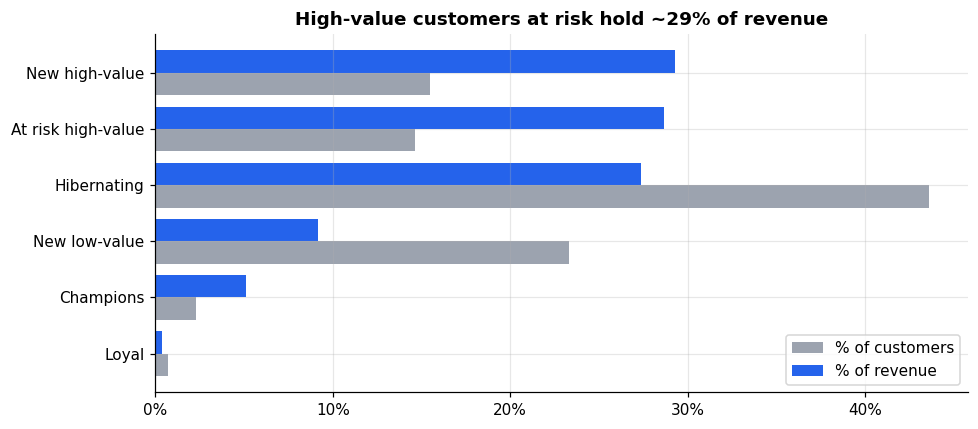

In [12]:
s = seg.sort_values("pct_revenue")
fig, ax = plt.subplots(figsize=(9, 4))
y = np.arange(len(s))
ax.barh(y - 0.2, s["pct_customers"], height=0.4, color=GREY, label="% of customers")
ax.barh(y + 0.2, s["pct_revenue"], height=0.4, color=BLUE, label="% of revenue")
ax.set_yticks(y, s.index)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.legend(loc="lower right")
ax.set_title("High-value customers at risk hold ~29% of revenue")
fig.tight_layout(); fig.savefig(FIG / "rfm_segments.png"); plt.show()

## 6. Cohort retention

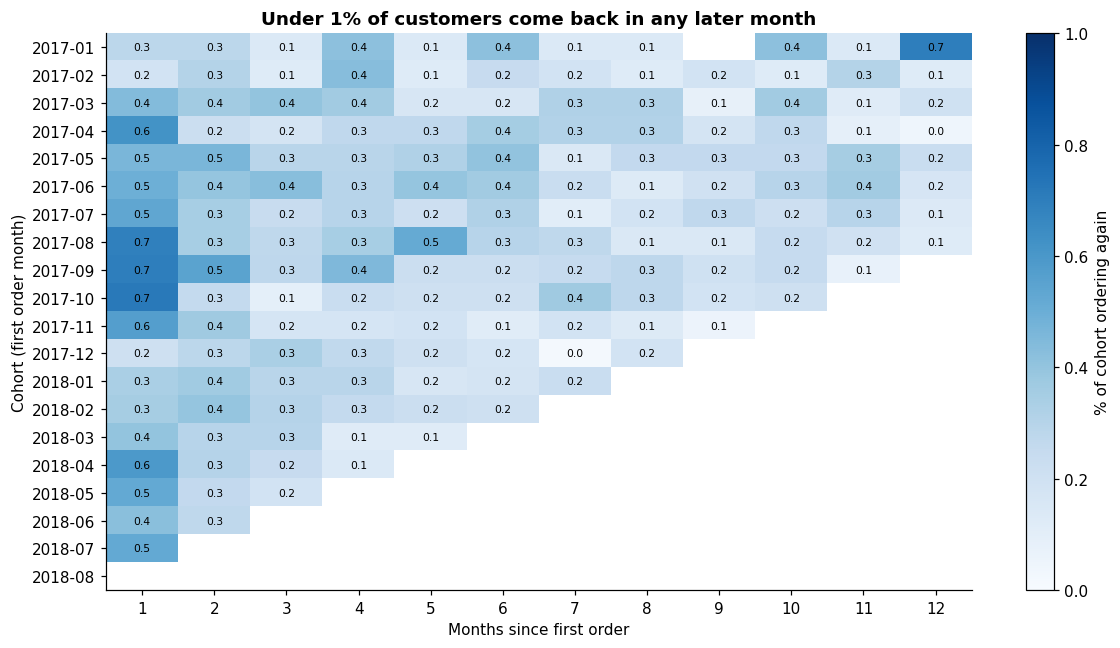

In [13]:
first = delivered.groupby("customer_unique_id")["order_purchase_timestamp"].min().dt.to_period("M")
c = delivered[["customer_unique_id", "order_purchase_timestamp"]].copy()
c["cohort"] = c["customer_unique_id"].map(first)
c["month_n"] = (c["order_purchase_timestamp"].dt.to_period("M") - c["cohort"]).apply(lambda x: x.n)
cohort = c.groupby(["cohort", "month_n"])["customer_unique_id"].nunique().unstack()
retention = cohort.div(cohort[0], axis=0) * 100

# Only show months each cohort has actually lived through
last = delivered["order_purchase_timestamp"].max().to_period("M")
for coh in retention.index:
    retention.loc[coh, retention.columns > (last - coh).n] = np.nan

r = retention.loc[:, 1:12]
fig, ax = plt.subplots(figsize=(11, 6))
im = ax.imshow(r.values, cmap="Blues", aspect="auto", vmin=0, vmax=1)
ax.set_xticks(range(r.shape[1]), r.columns)
ax.set_yticks(range(r.shape[0]), r.index.astype(str))
for i in range(r.shape[0]):
    for j in range(r.shape[1]):
        if not np.isnan(r.values[i, j]):
            ax.text(j, i, f"{r.values[i, j]:.1f}", ha="center", va="center", fontsize=7)
ax.set_xlabel("Months since first order"); ax.set_ylabel("Cohort (first order month)")
ax.set_title("Under 1% of customers come back in any later month")
ax.grid(False)
fig.colorbar(im, ax=ax, label="% of cohort ordering again")
fig.tight_layout(); fig.savefig(FIG / "cohort_retention.png"); plt.show()

## 7. Export clean tables for Excel and Power BI

In [14]:
out = ROOT / "data" / "processed"
order_cols = ["order_id", "customer_unique_id", "customer_city", "customer_state", "order_status",
              "purchase_date", "purchase_month", "n_items", "revenue", "freight", "payment_type",
              "installments", "review_score", "delivery_days", "days_vs_estimate", "is_late"]
o[order_cols].to_csv(out / "orders_clean.csv", index=False)

item_out = (items.merge(products[["product_id", "category"]], on="product_id")
            .merge(df["sellers"][["seller_id", "seller_state"]], on="seller_id")
            .merge(o[["order_id", "purchase_date", "order_status"]], on="order_id"))
item_out[["order_id", "order_item_id", "product_id", "category", "seller_id", "seller_state",
          "purchase_date", "order_status", "price", "freight_value"]].to_csv(out / "order_items_clean.csv", index=False)

rfm.reset_index().to_csv(out / "customers_rfm.csv", index=False)
print("Exported:", [p.name for p in out.glob("*_clean.csv")] + ["customers_rfm.csv"])

Exported: ['orders_clean.csv', 'order_items_clean.csv', 'customers_rfm.csv']


## Key findings

1. **Growth then plateau:** monthly revenue grew from R$ 112k (Jan 2017) to ~R$ 950k in
   2018, with a Black Friday spike in Nov 2017 (+52% MoM). Growth stalled from Mar 2018.
2. **Late delivery is the biggest driver of bad reviews:** on-time orders average 4.29
   stars; orders 8+ days late average 1.70, and 79% of them get 1-2 stars.
3. **Lateness is regional and seasonal:** the northeast (MA 17.5%, CE 13.8%) and RJ (12.1%)
   lag behind SP (4.5%). Late rates hit 19% in Mar 2018 after the holiday peak.
4. **Almost nobody comes back:** 97% of customers ordered once, and monthly retention
   stays under 1%. Repeat buyers are the largest untapped lever.
5. **Revenue is concentrated:** the top 10% of sellers earn 67% of revenue, and the top 15
   categories earn 76%.

**Recommendations:** fix delivery promises in the northeast and RJ (or set more realistic
estimates there); add logistics capacity before seasonal peaks; launch a second-purchase
campaign aimed at the "New high-value" and "At risk high-value" segments; and put
high-volume, low-rated sellers into a quality program.